<a href="https://colab.research.google.com/github/abuzarnavid48-p/HAR-Walking-Recognition/blob/main/human_activity_walking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))

Saving Acceleration with g 2026-11-09 21-46-38.zip to Acceleration with g 2026-11-09 21-46-38 (1).zip
Uploaded: ['Acceleration with g 2026-11-09 21-46-38 (1).zip']


In [ ]:
import zipfile
import os

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/acceleration_data')

print("Files extracted successfully!")

Files extracted successfully!


In [ ]:
import os

folder = '/content/acceleration_data'

for root, dirs, files in os.walk(folder):
    for file in files:
        if file.endswith('.csv'):
            print("CSV file found:", file)

CSV file found: Raw Data.csv
CSV file found: time.csv
CSV file found: device.csv


In [ ]:
import pandas as pd
import os

folder = '/content/acceleration_data'

for filename in ['Raw Data.csv', 'time.csv', 'device.csv']:
    path = os.path.join(folder, filename)

    print("\n" + "="*50)
    print("FILE:", filename)
    print("="*50)

    data = pd.read_csv(path)
    display(data.head(20))

    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())


FILE: Raw Data.csv


,Time (s),Acceleration x (m/s^2),Acceleration y (m/s^2),Acceleration z (m/s^2),Absolute acceleration (m/s^2)
0,0.008573,0.660800,1.101333,9.756371,9.840547
1,0.010619,0.663194,1.115698,9.739613,9.825714
2,0.012724,0.677559,1.146823,9.667787,9.759118
3,0.014708,0.703895,1.158794,9.603143,9.698382
4,0.016722,0.715866,1.165976,9.579201,9.676417
5,0.018706,0.696713,1.201889,9.504981,9.605967
6,0.020720,0.679953,1.225831,9.457097,9.560423
7,0.022703,0.670376,1.249773,9.428367,9.534434
8,0.024719,0.624887,1.268927,9.380483,9.486523
9,0.026701,0.577003,1.321599,9.306262,9.417328


Shape: (60000, 5)
Columns: ['Time (s)', 'Acceleration x (m/s^2)', 'Acceleration y (m/s^2)', 'Acceleration z (m/s^2)', 'Absolute acceleration (m/s^2)']

FILE: time.csv


FileNotFoundError: [Errno 2] No such file or directory: '/content/acceleration_data/time.csv'

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    '/content/acceleration_data/Raw Data.csv'
)

print("Dataset information:")
print(df.info())

print("\nFirst 10 readings:")
display(df.head(10))

print("\nStatistical analysis:")
display(df.describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Time (s)                       60000 non-null  float64
 1   Acceleration x (m/s^2)         60000 non-null  float64
 2   Acceleration y (m/s^2)         60000 non-null  float64
 3   Acceleration z (m/s^2)         60000 non-null  float64
 4   Absolute acceleration (m/s^2)  60000 non-null  float64
dtypes: float64(5)
memory usage: 2.3 MB
None

First 10 readings:


,Time (s),Acceleration x (m/s^2),Acceleration y (m/s^2),Acceleration z (m/s^2),Absolute acceleration (m/s^2)
0,0.008573,0.660800,1.101333,9.756371,9.840547
1,0.010619,0.663194,1.115698,9.739613,9.825714
2,0.012724,0.677559,1.146823,9.667787,9.759118
3,0.014708,0.703895,1.158794,9.603143,9.698382
4,0.016722,0.715866,1.165976,9.579201,9.676417
5,0.018706,0.696713,1.201889,9.504981,9.605967
6,0.020720,0.679953,1.225831,9.457097,9.560423
7,0.022703,0.670376,1.249773,9.428367,9.534434
8,0.024719,0.624887,1.268927,9.380483,9.486523
9,0.026701,0.577003,1.321599,9.306262,9.417328



Statistical analysis:


,Time (s),Acceleration x (m/s^2),Acceleration y (m/s^2),Acceleration z (m/s^2),Absolute acceleration (m/s^2)
count,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000
mean,60.008261,-0.373162,0.989432,9.913181,10.038384
std,34.641569,0.767362,0.857851,1.230443,1.207872
min,0.008573,-4.769250,-4.082114,5.427655,5.872690
25%,30.008972,-0.842759,0.476446,9.117120,9.259444
50%,60.008375,-0.339977,1.039083,9.842564,9.969517
75%,90.007933,0.119710,1.575385,10.591949,10.702457
max,120.007518,3.924097,4.098873,16.393099,16.501150


In [ ]:
print("Starting time:", df['Time (s)'].min())
print("Ending time:", df['Time (s)'].max())
print("Total duration:", df['Time (s)'].max() - df['Time (s)'].min(), "seconds")

Starting time: 0.008573037
Ending time: 120.0075175
Total duration: 119.998944463 seconds


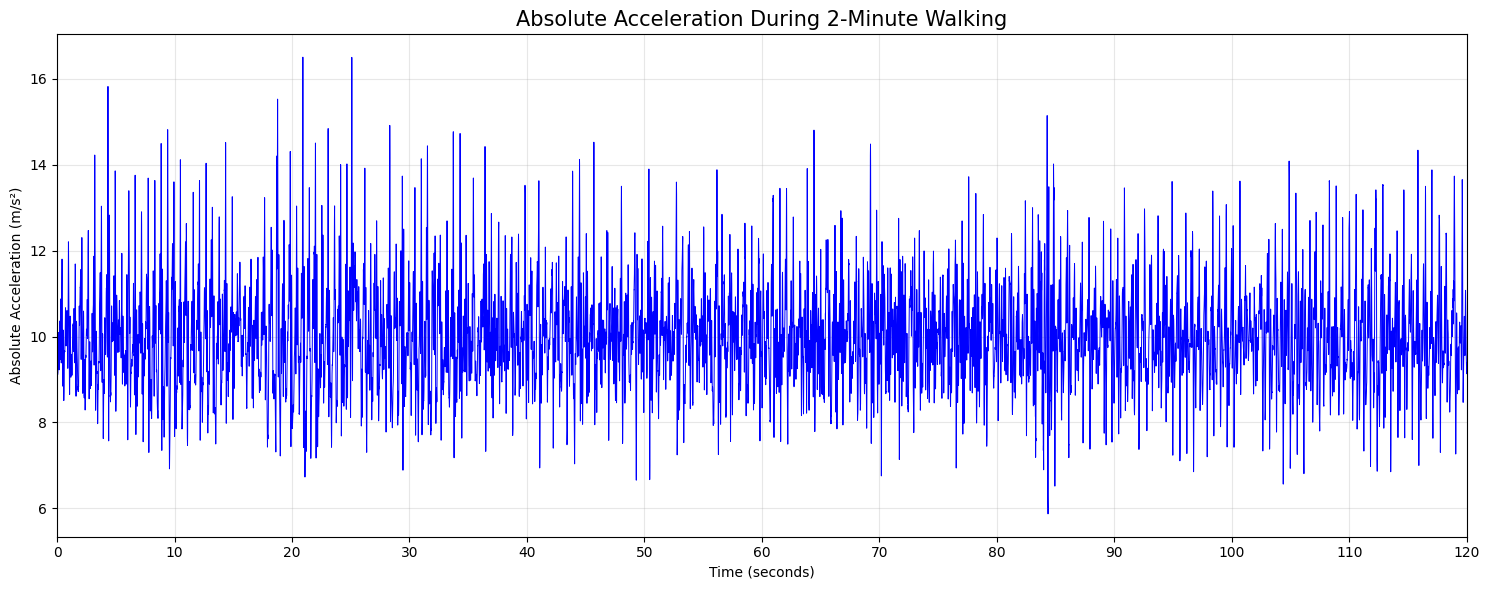

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    df['Time (s)'],
    df['Absolute acceleration (m/s^2)'],
    color='blue',
    linewidth=0.7
)

plt.title('Absolute Acceleration During 2-Minute Walking',
          fontsize=15)

plt.xlabel('Time (seconds)')
plt.ylabel('Absolute Acceleration (m/s²)')

plt.xlim(0, 120)
plt.xticks(range(0, 121, 10))

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig('2_minute_walking_graph.png', dpi=300)
plt.show()

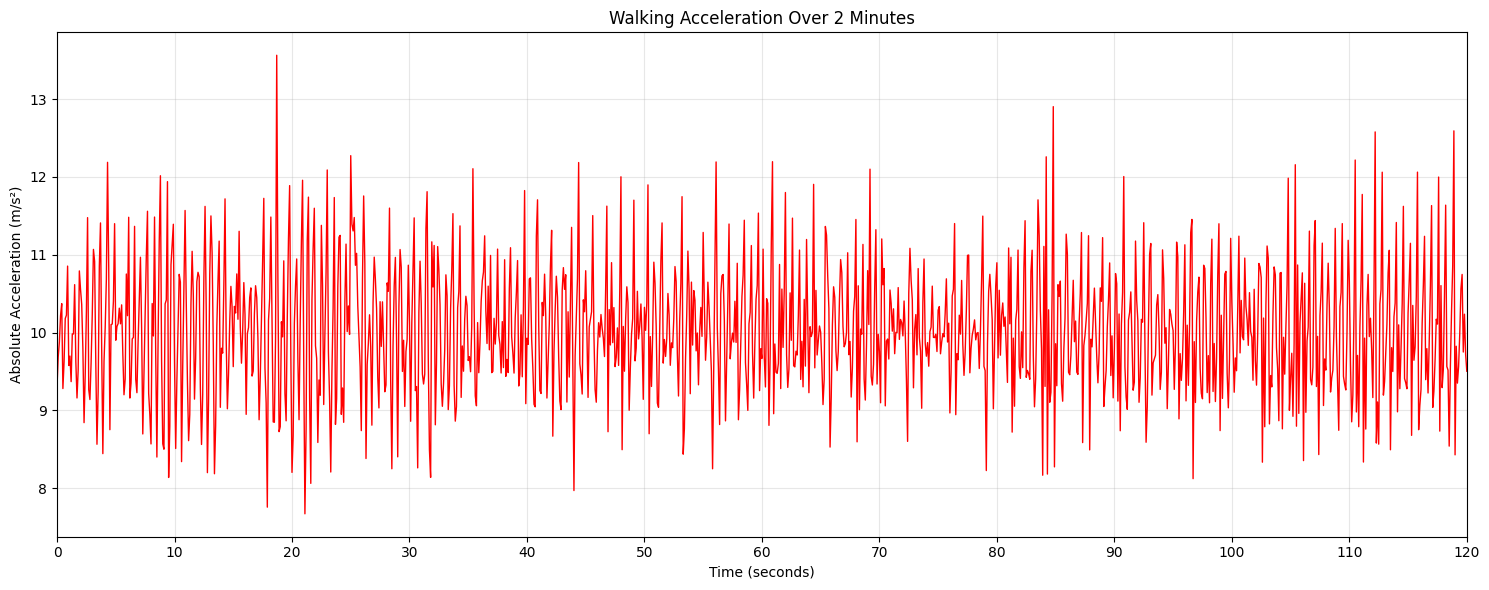

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Group measurements into 0.1-second intervals
df['Time interval'] = (df['Time (s)'] * 10).astype(int) / 10

smooth_df = df.groupby('Time interval')[
    'Absolute acceleration (m/s^2)'
].mean().reset_index()

# Plot
plt.figure(figsize=(15, 6))

plt.plot(
    smooth_df['Time interval'],
    smooth_df['Absolute acceleration (m/s^2)'],
    color='red',
    linewidth=1
)

plt.title('Walking Acceleration Over 2 Minutes')
plt.xlabel('Time (seconds)')
plt.ylabel('Absolute Acceleration (m/s²)')

plt.xlim(0, 120)
plt.xticks(range(0, 121, 10))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [2]:
import pandas as pd
from google.colab import files
import io

# Upload raw walking sensor data
uploaded = files.upload()

# Read the CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# Display the dataset
print("PRIVATE WALKING DATASET")
print("First 5 rows:")
display(df.head())

# Show columns and data types
print("Dataset information:")
df.info()

# Check dataset size
print("Dataset shape:", df.shape)

Saving Raw Data.csv to Raw Data.csv
PRIVATE WALKING DATASET
First 5 rows:


,Time (s),Acceleration x (m/s^2),Acceleration y (m/s^2),Acceleration z (m/s^2),Absolute acceleration (m/s^2)
0,0.008573,0.660800,1.101333,9.756371,9.840547
1,0.010619,0.663194,1.115698,9.739613,9.825714
2,0.012724,0.677559,1.146823,9.667787,9.759118
3,0.014708,0.703895,1.158794,9.603143,9.698382
4,0.016722,0.715866,1.165976,9.579201,9.676417


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Time (s)                       60000 non-null  float64
 1   Acceleration x (m/s^2)         60000 non-null  float64
 2   Acceleration y (m/s^2)         60000 non-null  float64
 3   Acceleration z (m/s^2)         60000 non-null  float64
 4   Absolute acceleration (m/s^2)  60000 non-null  float64
dtypes: float64(5)
memory usage: 2.3 MB
Dataset shape: (60000, 5)


In [5]:
# STEP 4: DATA QUALITY CHECK AND CLEANING

# Make a copy of the original dataset
clean_df = df.copy()

# Check missing values
print("Missing values:")
print(clean_df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:")
print(clean_df.duplicated().sum())

# Remove duplicate rows
clean_df = clean_df.drop_duplicates()

# Sort data by time
clean_df = clean_df.sort_values("Time (s)")

# Check time range
print("\nRecording starts at:", clean_df["Time (s)"].min(), "seconds")
print("Recording ends at:", clean_df["Time (s)"].max(), "seconds")

# Check acceleration statistics
print("\nAcceleration summary:")
display(clean_df.describe())

# Display cleaned dataset size
print("\nCleaned dataset shape:", clean_df.shape)

Missing values:
Time (s)                         0
Acceleration x (m/s^2)           0
Acceleration y (m/s^2)           0
Acceleration z (m/s^2)           0
Absolute acceleration (m/s^2)    0
dtype: int64

Duplicate rows:
0

Recording starts at: 0.008573037 seconds
Recording ends at: 120.0075175 seconds

Acceleration summary:


,Time (s),Acceleration x (m/s^2),Acceleration y (m/s^2),Acceleration z (m/s^2),Absolute acceleration (m/s^2)
count,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000
mean,60.008261,-0.373162,0.989432,9.913181,10.038384
std,34.641569,0.767362,0.857851,1.230443,1.207872
min,0.008573,-4.769250,-4.082114,5.427655,5.872690
25%,30.008972,-0.842759,0.476446,9.117120,9.259444
50%,60.008375,-0.339977,1.039083,9.842564,9.969517
75%,90.007933,0.119710,1.575385,10.591949,10.702457
max,120.007518,3.924097,4.098873,16.393099,16.501150



Cleaned dataset shape: (60000, 5)


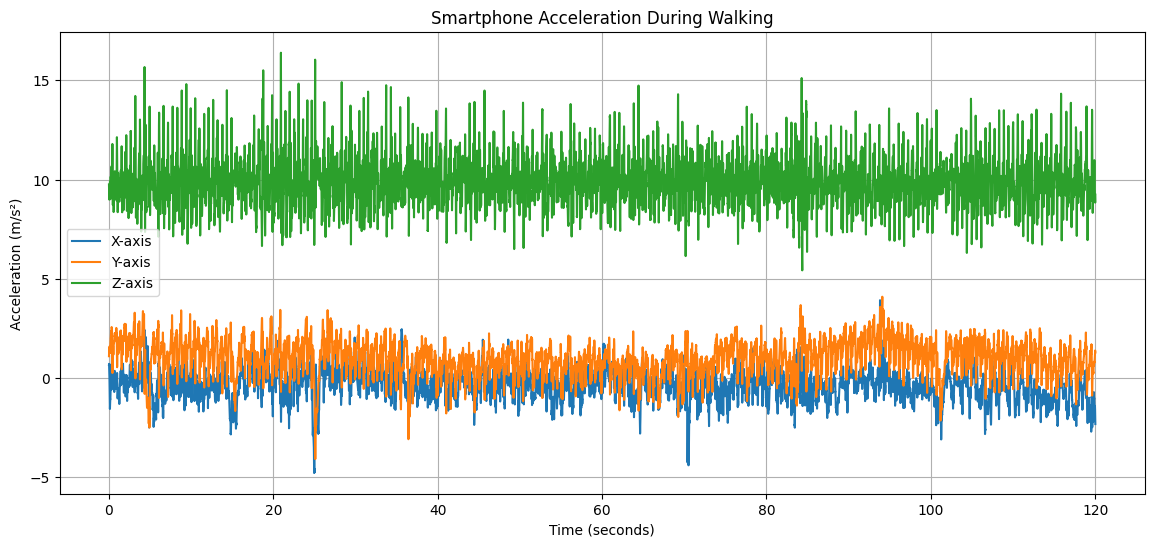

In [6]:
import matplotlib.pyplot as plt

# Plot acceleration on all three axes
plt.figure(figsize=(14, 6))

plt.plot(clean_df["Time (s)"],
         clean_df["Acceleration x (m/s^2)"],
         label="X-axis")

plt.plot(clean_df["Time (s)"],
         clean_df["Acceleration y (m/s^2)"],
         label="Y-axis")

plt.plot(clean_df["Time (s)"],
         clean_df["Acceleration z (m/s^2)"],
         label="Z-axis")

plt.title("Smartphone Acceleration During Walking")
plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (m/s²)")
plt.legend()
plt.grid(True)
plt.show()